<a href="https://colab.research.google.com/github/Amulya951/Google_collab/blob/master/TicTacToe_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tic-Tac-Toe vs Computer using an Artificial Neural Network (ANN)

**Dataset:** `tictactoe_games.csv` — every possible game of Tic-Tac-Toe (255,168 games). Each row lists the moves in order (`row-col`, `---` = game already over) and the winner (`X`, `O`, or `-` for a draw).

**Approach**
1. Replay every game in the dataset to collect all board positions and the moves that connect them (the full game tree).
2. Use the game results from the dataset to label each position with its **best move(s)** (minimax: work backwards from the final results).
3. Train an **ANN** (Keras, fully-connected network) that takes a board as input and outputs a probability for each of the 9 squares.
4. The computer plays by choosing the legal square the ANN rates highest.
5. Test the ANN against a random player and a perfect player, then **play against it yourself**.

> Run the cells from top to bottom (**Runtime → Run all**). When asked, upload `tictactoe_games.csv`.

## 1. Import libraries

In [ ]:
import os
import random
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# Fix random seeds so results are repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the dataset
If the CSV is not already in the Colab file panel, an upload button will appear.

In [ ]:
CSV_PATH = "tictactoe_games.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Please upload tictactoe_games.csv")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Put tictactoe_games.csv in the same folder as this notebook.")

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")
print("Shape:", df.shape)
df.head()

Shape: (255168, 10)


,Winner,Move 1-X (Row-Col),Move 2-O (Row-Col),Move 3-X (Row-Col),Move 4-O (Row-Col),Move 5-X (Row-Col),Move 6-O (Row-Col),Move 7-X (Row-Col),Move 8-O (Row-Col),Move 9-X (Row-Col)
0,X,0-0,0-1,1-0,0-2,2-0,---,---,---,---
1,X,0-0,0-1,1-0,1-1,2-0,---,---,---,---
2,X,0-0,0-1,1-0,1-2,2-0,---,---,---,---
3,X,0-0,0-1,1-0,2-1,2-0,---,---,---,---
4,X,0-0,0-1,1-0,2-2,2-0,---,---,---,---


## 3. Explore the data

Winner
X       131184
O        77904
Draw     46080
Name: count, dtype: int64


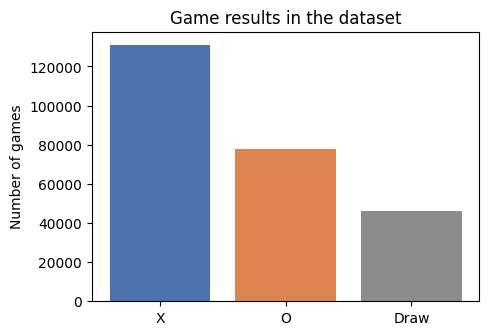


Number of moves per game:
5      1440
6      5328
7     47952
8     72576
9    127872
Name: count, dtype: int64


In [ ]:
print(df["Winner"].value_counts().rename({"-": "Draw"}))

counts = df["Winner"].replace({"-": "Draw"}).value_counts()
plt.figure(figsize=(5, 3.5))
plt.bar(counts.index, counts.values, color=["#4C72B0", "#DD8452", "#8C8C8C"])
plt.title("Game results in the dataset")
plt.ylabel("Number of games")
plt.show()

# How long are the games?
move_cols = df.columns[1:]
game_length = (df[move_cols] != "---").sum(axis=1)
print("\nNumber of moves per game:")
print(game_length.value_counts().sort_index())

## 4. Replay every game to build the game tree

A board is stored as a tuple of 9 cells (index `row*3 + col`):

```
 0 | 1 | 2
 3 | 4 | 5
 6 | 7 | 8
```
Each cell is `'X'`, `'O'` or `' '` (empty).

For every position we record which moves were played from it (and the position they lead to), and for every finished position we record the winner given in the dataset.

In [ ]:
EMPTY = (" ",) * 9

children = {}     # position -> {move_index: next_position}
final_result = {} # finished position -> 'X', 'O' or '-'

for row in df.itertuples(index=False):
    winner = row[0]
    moves = [m for m in row[1:] if m != "---"]

    board = list(EMPTY)
    for turn, m in enumerate(moves):
        r, c = map(int, m.split("-"))
        idx = r * 3 + c
        before = tuple(board)
        board[idx] = "X" if turn % 2 == 0 else "O"   # X always moves first
        after = tuple(board)
        children.setdefault(before, {})[idx] = after

    final_result[tuple(board)] = winner

print("Positions where a move is needed:", len(children))
print("Finished positions (game over):  ", len(final_result))

Positions where a move is needed: 4520
Finished positions (game over):   958


## 5. Label each position with its best move(s)

Using the results in the dataset, we score every position from **X's point of view** (minimax):

* finished position: X wins → `+(10 − moves played)`, O wins → `−(10 − moves played)`, draw → `0`
  (the `10 − moves` part makes the computer prefer a *quick* win and a *slow* loss)
* otherwise: if it is X's turn, take the **maximum** score of the next positions; if it is O's turn, take the **minimum**.

The move(s) that achieve that best score are the "correct answer" the ANN has to learn.

In [ ]:
def player_to_move(board):
    # X moves when both players have the same number of marks
    return "X" if board.count("X") == board.count("O") else "O"

@lru_cache(maxsize=None)
def score(board):
    if board in final_result:
        n = 9 - board.count(" ")
        w = final_result[board]
        if w == "X":
            return 10 - n
        if w == "O":
            return -(10 - n)
        return 0
    child_scores = [score(nxt) for nxt in children[board].values()]
    return max(child_scores) if player_to_move(board) == "X" else min(child_scores)

def best_moves(board):
    move_scores = {m: score(nxt) for m, nxt in children[board].items()}
    target = max(move_scores.values()) if player_to_move(board) == "X" else min(move_scores.values())
    return [m for m, s in move_scores.items() if s == target]

print("Score of the empty board:", score(EMPTY), "(0 = perfect play is a draw)")
print("Best first moves for X:", best_moves(EMPTY))

Score of the empty board: 0 (0 = perfect play is a draw)
Best first moves for X: [0, 1, 2, 3, 4, 5, 6, 7, 8]


## 6. Prepare the training data for the ANN

**Input (9 numbers):** the board from the point of view of the player who is about to move —
`+1` = my mark, `−1` = opponent's mark, `0` = empty.
This way one network can play both as X and as O.

**Output (9 numbers):** the best move(s). If there are 2 equally good moves, each gets `0.5`, and so on.

In [ ]:
def encode(board, me):
    return np.array([1 if c == me else (-1 if c != " " else 0) for c in board], dtype=np.float32)

X_data, y_data, best_lists, boards = [], [], [], []

for board in children:
    me = player_to_move(board)
    good = best_moves(board)
    target = np.zeros(9, dtype=np.float32)
    target[good] = 1.0 / len(good)

    X_data.append(encode(board, me))
    y_data.append(target)
    best_lists.append(good)
    boards.append(board)

X_data = np.array(X_data)
y_data = np.array(y_data)

print("X shape:", X_data.shape)
print("y shape:", y_data.shape)
print("\nExample input :", X_data[5])
print("Example target:", y_data[5])

X shape: (4520, 9)
y shape: (4520, 9)

Example input : [ 1. -1.  0.  1. -1.  0.  0.  0.  0.]
Example target: [0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [ ]:
idx = np.arange(len(X_data))
train_idx, test_idx = train_test_split(idx, test_size=0.15, random_state=SEED)

X_train, y_train = X_data[train_idx], y_data[train_idx]
X_test,  y_test  = X_data[test_idx],  y_data[test_idx]

print("Training positions:", len(X_train))
print("Testing positions: ", len(X_test))

Training positions: 3842
Testing positions:  678


## 7. Build the ANN model

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(9,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(9, activation="softmax")   # one probability per square
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,409 (400.04 KB)

 Trainable params: 102,409 (400.04 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the model

Training finished.


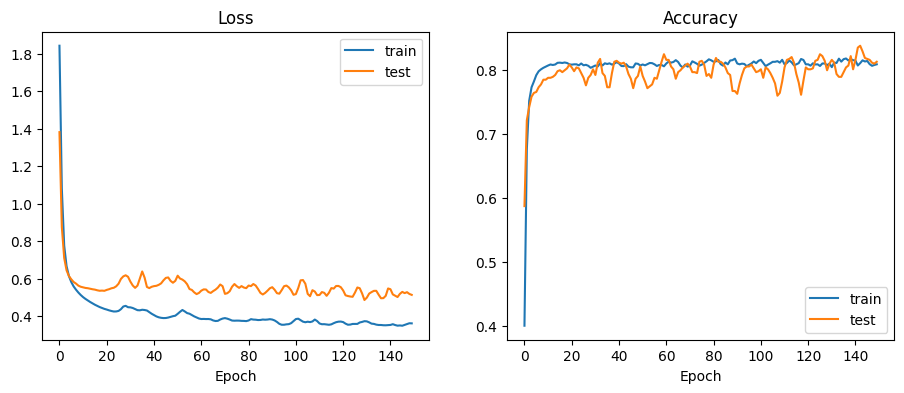

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=150,
    batch_size=64,
    verbose=0
)
print("Training finished.")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="test")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="test")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.show()

## 9. Evaluate: does the ANN pick a best move?

Keras "accuracy" only checks one of the best moves. A fairer measure: the move the ANN picks (ignoring occupied squares) is **any** of the best moves.

In [ ]:
def ann_choice(probs, board):
    probs = probs.copy()
    for i, c in enumerate(board):
        if c != " ":
            probs[i] = -1          # never choose an occupied square
    return int(np.argmax(probs))

def best_move_accuracy(indices):
    preds = model.predict(X_data[indices], verbose=0)
    correct = sum(ann_choice(p, boards[i]) in best_lists[i] for p, i in zip(preds, indices))
    return correct / len(indices)

print(f"Best-move accuracy on TRAIN positions: {best_move_accuracy(train_idx):.2%}")
print(f"Best-move accuracy on TEST positions (never seen): {best_move_accuracy(test_idx):.2%}")

Best-move accuracy on TRAIN positions: 100.00%
Best-move accuracy on TEST positions (never seen): 99.26%


### Final training on all positions
The test score shows the network has learned general patterns. For the actual game we want the computer to be as strong as possible, so we now train a few more epochs on **every** position.

In [ ]:
model.fit(X_data, y_data, epochs=100, batch_size=64, verbose=0)
print(f"Best-move accuracy on ALL positions: {best_move_accuracy(idx):.2%}")

Best-move accuracy on ALL positions: 100.00%


## 10. Let the ANN play some test matches

In [ ]:
LINES = [(0,1,2),(3,4,5),(6,7,8),(0,3,6),(1,4,7),(2,5,8),(0,4,8),(2,4,6)]

def check_winner(board):
    for a, b, c in LINES:
        if board[a] != " " and board[a] == board[b] == board[c]:
            return board[a]
    if " " not in board:
        return "Draw"
    return None

def computer_move(board):
    me = player_to_move(board)
    probs = model.predict(encode(board, me).reshape(1, 9), verbose=0)[0]
    return ann_choice(probs, board)

def random_move(board):
    return random.choice([i for i, c in enumerate(board) if c == " "])

def perfect_move(board):
    return random.choice(best_moves(tuple(board)))

def play_match(x_player, o_player):
    board = [" "] * 9
    while check_winner(board) is None:
        mover = x_player if player_to_move(board) == "X" else o_player
        board[mover(board)] = player_to_move(board)
    return check_winner(board)

def tournament(x_player, o_player, games):
    results = {"X": 0, "O": 0, "Draw": 0}
    for _ in range(games):
        results[play_match(x_player, o_player)] += 1
    return results

N = 100
print("ANN (X)     vs Random (O): ", tournament(computer_move, random_move, N))
print("Random (X)  vs ANN (O):    ", tournament(random_move, computer_move, N))
print("ANN (X)     vs Perfect (O):", tournament(computer_move, perfect_move, N))
print("Perfect (X) vs ANN (O):    ", tournament(perfect_move, computer_move, N))

ANN (X)     vs Random (O):  {'X': 98, 'O': 0, 'Draw': 2}
Random (X)  vs ANN (O):     {'X': 0, 'O': 79, 'Draw': 21}
ANN (X)     vs Perfect (O): {'X': 0, 'O': 0, 'Draw': 100}
Perfect (X) vs ANN (O):     {'X': 0, 'O': 0, 'Draw': 100}


## 11. 🎮 Play against the computer

Click a square to play. Choose whether you want to be **X** (move first) or **O**, then press **New game**.

In [ ]:
import ipywidgets as widgets
from IPython.display import display

board = [" "] * 9
human = "X"
cells = [widgets.Button(description=" ", layout=widgets.Layout(width="80px", height="80px"))
         for _ in range(9)]
for b in cells:
    b.style.font_size = "28px"
    b.style.font_weight = "bold"

status = widgets.HTML()
side = widgets.ToggleButtons(options=["X", "O"], description="You play:")
new_btn = widgets.Button(description="New game", button_style="primary")
score_board = {"You": 0, "Computer": 0, "Draw": 0}

def refresh():
    for i, b in enumerate(cells):
        b.description = board[i]
        b.disabled = board[i] != " " or check_winner(board) is not None
        b.style.button_color = "#cfe2ff" if board[i] == "X" else ("#ffd6cc" if board[i] == "O" else None)

def show_status():
    w = check_winner(board)
    if w is None:
        msg = "Your turn"
    else:
        if w == "Draw":
            msg = "It's a draw 🤝"; score_board["Draw"] += 1
        elif w == human:
            msg = "You win! 🎉"; score_board["You"] += 1
        else:
            msg = "Computer wins 🤖"; score_board["Computer"] += 1
    status.value = (f"<h3 style='margin:4px'>{msg}</h3>"
                    f"You {score_board['You']} · Computer {score_board['Computer']} · Draws {score_board['Draw']}")

def computer_turn():
    if check_winner(board) is None and player_to_move(board) != human:
        board[computer_move(board)] = player_to_move(board)

def on_cell(btn):
    i = cells.index(btn)
    if board[i] != " " or check_winner(board) is not None or player_to_move(board) != human:
        return
    board[i] = human
    computer_turn()
    refresh(); show_status()

def on_new(_):
    global board, human
    board = [" "] * 9
    human = side.value
    computer_turn()          # computer opens if you chose O
    refresh(); show_status()

for b in cells:
    b.on_click(on_cell)
new_btn.on_click(on_new)

grid = widgets.GridBox(cells, layout=widgets.Layout(grid_template_columns="repeat(3, 84px)"))
display(widgets.VBox([widgets.HBox([side, new_btn]), grid, status]))
on_new(None)

### Text version (backup)
If the buttons above don't show up, run this cell instead. Type a square number 1–9:
```
 1 | 2 | 3
 4 | 5 | 6
 7 | 8 | 9
```

In [ ]:
def print_board(b):
    for r in range(3):
        print(" " + " | ".join(b[r*3 + c] if b[r*3 + c] != " " else str(r*3 + c + 1) for c in range(3)))
        if r < 2:
            print("---+---+---")

def play_text_game():
    me = ""
    while me not in ("X", "O"):
        me = input("Do you want to be X (first) or O (second)? ").strip().upper()
    b = [" "] * 9
    while check_winner(b) is None:
        if player_to_move(b) == me:
            print_board(b)
            choice = input("Your move (1-9): ").strip()
            if not choice.isdigit() or not 1 <= int(choice) <= 9 or b[int(choice) - 1] != " ":
                print("Invalid move, try again.")
                continue
            b[int(choice) - 1] = me
        else:
            m = computer_move(b)
            b[m] = player_to_move(b)
            print(f"\nComputer plays square {m + 1}")
    print_board(b)
    w = check_winner(b)
    print("\nResult:", "Draw!" if w == "Draw" else ("You win!" if w == me else "Computer wins!"))

play_text_game()

Do you want to be X (first) or O (second)? x
 1 | 2 | 3
---+---+---
 4 | 5 | 6
---+---+---
 7 | 8 | 9
Your move (1-9): 4

Computer plays square 7
 1 | 2 | 3
---+---+---
 X | 5 | 6
---+---+---
 O | 8 | 9
Your move (1-9): 6

Computer plays square 5
 1 | 2 | 3
---+---+---
 X | O | X
---+---+---
 O | 8 | 9
Your move (1-9): 3

Computer plays square 9
 1 | 2 | X
---+---+---
 X | O | X
---+---+---
 O | 8 | O
Your move (1-9): 1

Computer plays square 8
 X | 2 | X
---+---+---
 X | O | X
---+---+---
 O | O | O

Result: Computer wins!


In [ ]:
# ============================================================
#  🎮 Tic-Tac-Toe UI  (paste into a NEW cell and run it)
#  Needs the earlier cells to have been run first, because it
#  uses your trained ANN through the computer_move() function.
# ============================================================
import uuid
from IPython.display import HTML, JSON, display

try:
    from google.colab import output
except ImportError:
    raise RuntimeError("This UI works inside Google Colab. Use the text version elsewhere.")

if "computer_move" not in globals():
    raise NameError("Run the training cells first (computer_move() is not defined yet).")

# --- Python side: the browser asks this function for the ANN's move ---
def _ui_ai_move(board_text):
    # board_text is 9 characters: X, O or . (empty)
    board_list = [" " if ch == "." else ch for ch in board_text]
    return JSON({"move": int(computer_move(board_list))})

output.register_callback("ttt_ai_move", _ui_ai_move)

# --- Browser side: the game board ---
UI_ID = "ttt" + uuid.uuid4().hex[:8]

UI_HTML = """
<style>
  #__ID__ { font-family: 'Segoe UI', Roboto, Arial, sans-serif; max-width: 360px; margin: 10px auto;
            padding: 20px; border-radius: 18px; background: #1f2937; color: #f9fafb;
            box-shadow: 0 10px 30px rgba(0,0,0,.35); text-align: center; }
  #__ID__ h2 { margin: 0 0 4px; font-size: 22px; letter-spacing: .5px; }
  #__ID__ .sub { font-size: 12px; color: #9ca3af; margin-bottom: 14px; }
  #__ID__ .side { display: flex; gap: 8px; justify-content: center; align-items: center; margin-bottom: 14px; font-size: 14px; }
  #__ID__ .side button { padding: 6px 16px; border-radius: 999px; border: 2px solid #4b5563; background: transparent;
            color: #e5e7eb; font-weight: 700; cursor: pointer; }
  #__ID__ .side button.on { background: #6366f1; border-color: #6366f1; color: #fff; }
  #__ID__ .grid { display: grid; grid-template-columns: repeat(3, 96px); gap: 8px; justify-content: center; margin: 0 auto 14px; }
  #__ID__ .cell { width: 96px; height: 96px; border: none; border-radius: 14px; background: #374151;
            font-size: 52px; font-weight: 800; cursor: pointer; transition: transform .1s, background .2s; color: #f9fafb; }
  #__ID__ .cell:hover:not(:disabled) { background: #4b5563; transform: scale(1.04); }
  #__ID__ .cell:disabled { cursor: default; }
  #__ID__ .cell.X { color: #60a5fa; }
  #__ID__ .cell.O { color: #fb923c; }
  #__ID__ .cell.win { background: #166534; animation: pulse .8s infinite alternate; }
  @keyframes pulse { from { transform: scale(1); } to { transform: scale(1.07); } }
  #__ID__ .status { min-height: 28px; font-size: 18px; font-weight: 700; margin-bottom: 10px; }
  #__ID__ .score { display: flex; justify-content: space-around; font-size: 13px; color: #d1d5db; margin-bottom: 14px; }
  #__ID__ .score b { display: block; font-size: 22px; color: #fff; }
  #__ID__ .new { width: 100%; padding: 10px; border: none; border-radius: 10px; background: #6366f1;
            color: #fff; font-size: 15px; font-weight: 700; cursor: pointer; }
  #__ID__ .new:hover { background: #4f46e5; }
</style>

<div id="__ID__">
  <h2>Tic-Tac-Toe vs ANN</h2>
  <div class="sub">X always moves first</div>
  <div class="side">You play:
    <button class="on" data-side="X">X</button>
    <button data-side="O">O</button>
  </div>
  <div class="grid"></div>
  <div class="status"></div>
  <div class="score">
    <div><b data-s="you">0</b>You</div>
    <div><b data-s="draw">0</b>Draws</div>
    <div><b data-s="ai">0</b>Computer</div>
  </div>
  <button class="new">New game</button>
</div>

<script>
(function () {
  const root = document.getElementById("__ID__");
  const gridEl = root.querySelector(".grid");
  const statusEl = root.querySelector(".status");
  const LINES = [[0,1,2],[3,4,5],[6,7,8],[0,3,6],[1,4,7],[2,5,8],[0,4,8],[2,4,6]];

  let board, human = "X", over, busy;
  const score = { you: 0, draw: 0, ai: 0 };

  // build the 9 squares
  const cells = [];
  for (let i = 0; i < 9; i++) {
    const b = document.createElement("button");
    b.className = "cell";
    b.onclick = () => humanMove(i);
    gridEl.appendChild(b);
    cells.push(b);
  }

  function findWinner(b) {
    for (const l of LINES) {
      if (b[l[0]] && b[l[0]] === b[l[1]] && b[l[1]] === b[l[2]]) return { who: b[l[0]], line: l };
    }
    return b.every(c => c) ? { who: "Draw", line: [] } : null;
  }

  function turn() {            // whose turn is it?
    const x = board.filter(c => c === "X").length, o = board.filter(c => c === "O").length;
    return x === o ? "X" : "O";
  }

  function draw() {
    const res = findWinner(board);
    cells.forEach((c, i) => {
      c.textContent = board[i] || "";
      c.className = "cell" + (board[i] ? " " + board[i] : "") + (res && res.line.includes(i) ? " win" : "");
      c.disabled = !!board[i] || over || busy || turn() !== human;
    });
  }

  function finish() {
    const res = findWinner(board);
    if (!res) return false;
    over = true;
    if (res.who === "Draw")      { score.draw++; statusEl.textContent = "It's a draw 🤝"; }
    else if (res.who === human)  { score.you++;  statusEl.textContent = "You win! 🎉"; }
    else                         { score.ai++;   statusEl.textContent = "Computer wins 🤖"; }
    root.querySelector('[data-s="you"]').textContent  = score.you;
    root.querySelector('[data-s="draw"]').textContent = score.draw;
    root.querySelector('[data-s="ai"]').textContent   = score.ai;
    return true;
  }

  async function computerMove() {
    if (over || turn() === human) return;
    busy = true; statusEl.textContent = "Computer is thinking…"; draw();
    const text = board.map(c => c || ".").join("");
    try {
      const reply = await google.colab.kernel.invokeFunction("ttt_ai_move", [text], {});
      const move = reply.data["application/json"].move;
      await new Promise(r => setTimeout(r, 350));       // small pause so it feels natural
      board[move] = turn();
    } catch (e) {
      statusEl.textContent = "Error: run the training cells first.";
      busy = false; draw(); return;
    }
    busy = false;
    if (!finish()) statusEl.textContent = "Your turn (" + human + ")";
    draw();
  }

  function humanMove(i) {
    if (over || busy || board[i] || turn() !== human) return;
    board[i] = human;
    if (finish()) { draw(); return; }
    draw();
    computerMove();
  }

  function newGame() {
    board = Array(9).fill(""); over = false; busy = false;
    statusEl.textContent = human === "X" ? "Your turn (X)" : "";
    draw();
    computerMove();            // computer opens if you chose O
  }

  root.querySelectorAll(".side button").forEach(btn => {
    btn.onclick = () => {
      human = btn.dataset.side;
      root.querySelectorAll(".side button").forEach(b => b.classList.toggle("on", b === btn));
      newGame();
    };
  });
  root.querySelector(".new").onclick = newGame;

  newGame();
})();
</script>
""".replace("__ID__", UI_ID)

display(HTML(UI_HTML))

## Summary
* The dataset gave every possible game and its result, from which we extracted **all board positions** and the **best move** in each.
* A 3-hidden-layer ANN (256 → 256 → 128 neurons, softmax output over 9 squares) learned to map a board to the best move.
* The trained network beats a random player most of the time and holds a perfect player to a draw — so you can't beat it, the best you can do is draw!